# Monthly polio counts: forecasting and interpolation

US poliomyelitis cases reported monthly from 1970 to 1983 — the series
{cite:t}`zeger1988regression` modelled and read as evidence of a decrease
in the polio infection rate. This study runs the `autospec` search over a set of candidate specifications on it
using rolling-origin folds ordered by date. Each fold scores months after
its training window. Held-out dispersion supports NBinomial over Poisson,
but none of the tested specifications forecasts later months much better than
the training mean on these folds. Describing the decade and forecasting it are
separate questions, and the second half of the page answers the first on
folds that interpolate.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | a count series' trend and season: its forecast of later months, and its description of the decade |
| **Observed response** | `cases`, poliomyelitis cases reported in a month |
| **Estimand** | the held-out risk of candidate specifications on rolling-origin folds (forecast) and random folds (interpolation); the fitted monthly mean |
| **Units** | cases per month; held-out negative binomial risk per judged month |
| **Sampling unit** | one calendar month; each row is one month |
| **Dependence** | serial dependence between neighbouring months |
| **Split / resampling unit** | the rolling origin, which trains on the past and judges the block that follows; random months for the description |
| **Tuning** | the step count, cross-validated on each fold design |
| **Uncertainty** | cross-validated risk on fixed folds; no interval is attached to the trend description |
| **Claim type** | descriptive and predictive; no causal claim is made |
:::

In [1]:
import altair as alt
import numpy as np
import polars as pl

import mboostrs as mb
from mboostrs.autospec import autospec
from mboostrs.datasets import polio

series = polio()

rec0 = autospec(series, "cases")
print(rec0.report())


autospec: cases ~ brandom(year, df=4.0) + bbs(month, df=4.0) + bbs(date, df=4.0)

folds: rolling-origin 5-fold ordered by date: the past predicts the future, and only rows after the first half are judged (detected from the column's dates; pass folds= for another design)

response: Poisson counts (inferred from 11 whole-number values; if they are rounded measurements pass family=Gaussian(), and if they are ordered classes pass family=PropOdds(n_levels=11))

data hygiene (no fit -- scans only)
  year: 14 whole-number values behave as labels: the mean response varies between values 2.7 times as much as noise explains (4.2 standard deviations above no signal), and adjacent values differ as much as arbitrary pairs (adjacency ratio 0.61) -- fitted with brandom rather than a smooth, and detected as a grouping: the probes' folds hold whole groups out, so every measurement scores rows whose group the fit has not seen. Declare folds= to score a different population
  cases: 64 of 168 values are 

## Calendar-ordered folds and initial terms

The report specifies five rolling-origin folds ordered by `date`. Each fold
trains on earlier months and scores a later block; only the second half of the
series is scored. Random-row folds would instead allow later observations,
such as those from 1983, to help predict earlier months such as those in 1971.

The scan raises two real flags for a count series: 38% of the months
report zero cases, which a count family will fit through its mean, and
`year` is read as labels — fourteen whole-number values that vary 4.2
standard deviations across — so the rule for column types fits `brandom(year)`. A
time axis read as groups is a default, and the report says so; the
measured run decides what survives.


In [2]:
rec = autospec(series, "cases", budget=400, mstop=100)
print(rec.report())
import re

date_row = next(row for row in rec.evidence["shapes"] if row.column == "date")
# The line's advantage over the spline, and its size in paired fold standard
# errors, as the report states them.
date_gain = re.search(r"([\d.]+)% less held-out risk", date_row.sentence)
date_z = re.search(r"([\d.]+) paired fold standard errors", date_row.sentence)
dropped = dict(rec.evidence["deselect"].dropped) if "deselect" in rec.evidence else {}
date_dropped = next((term for term in dropped if "date" in term), None)


/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/_extrapolation.py:189: RuntimeWarning: tune_mstop: the chosen mstop=2 has a cross-validated risk of 1.50913, within 1.0% of the intercept-only risk of 1.51002 (mstop=0; relative gap 0.06%). The curve is flat and the fit is close to a constant: the terms add little that the out-of-fold risk can see at this sample size. Compare with the constant model before reporting the fitted effects. Pass flat_tolerance=None to silence this check, or a different tolerance.
  return fn(*args, **kwargs)


/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/_autospec.py:3732: UserWarning: Pearson residuals are not defined for NBinomial; falling back to the response-scale residual y - predict(type='response').
  residual = pearson_residual(fit, data, response)
/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/_extrapolation.py:189: RuntimeWarning: tune_mstop: the chosen mstop=2 has a cross-validated risk of 1.5216, within 1.0% of the intercept-only risk of 1.51002 (mstop=0; relative gap 0.77%). The curve is flat and the fit is close to a constant: the terms add little that the out-of-fold risk can see at this sample size. Compare with the constant model before reporting the fitted effects. Pass flat_tolerance=None to silence this check, or a different tolerance.
  return fn(*a

autospec: cases ~ brandom(year, df=4.0) + bols(month) + bols(date)

folds: rolling-origin 5-fold ordered by date: the past predicts the future, and only rows after the first half are judged (detected from the column's dates; pass folds= for another design)

response: Poisson counts (inferred from 11 whole-number values; if they are rounded measurements pass family=Gaussian(), and if they are ordered classes pass family=PropOdds(n_levels=11))

data hygiene (no fit -- scans only)
  year: 14 whole-number values behave as labels: the mean response varies between values 2.7 times as much as noise explains (4.2 standard deviations above no signal), and adjacent values differ as much as arbitrary pairs (adjacency ratio 0.61) -- fitted with brandom rather than a smooth, and detected as a grouping: the probes' folds hold whole groups out, so every measurement scores rows whose group the fit has not seen. Declare folds= to score a different population
  cases: 64 of 168 values are exactly zero (

## The measurements

The response's integer coding does not distinguish Poisson from NBinomial. Both Poisson
and NBinomial fit nearly the same mean; what separates them is the
spread, and the held-out Pearson dispersion is
{eval}`f"{rec.evidence['family'].dispersion:.2f}"` on the judged months,
above the 1.5 line, so NBinomial carries the extra variance.

The shape probe scores the date term as a spline, a straight line and a
tree, each at its own best step count on the rolling folds
({eval}`date_row.sentence.split(' — ')[0]`). The straight line is ahead by
{eval}`date_gain.group(1) if date_gain else "less than 2"`% of the held-out
risk, at {eval}`date_z.group(1) if date_z else "an unmeasured number of"` paired
fold standard errors: large enough for the probe's 2% rule (an alternative shape must lower held-out risk by at least 2%), and far inside
the fold-to-fold noise. It matters little here, because the tuned fit then
gives the date term {eval}`f"{dropped[date_dropped]:.2%}" if date_dropped else "a share above 1%"`
of its risk reduction, and deselection (removal, after fitting, of terms whose contribution is below a stated share)
{eval}`"drops it" if date_dropped else "keeps it"`. The step-count probe
settles at {eval}`int(rec.mstop)` steps. Neither remaining term can forecast a
new year: `brandom(year)` has no level for a year after its training rows and
predicts the average year there, and the month levels repeat the seasonal
pattern. The specifications that could forecast are priced on the same
rolling folds.

In [3]:
# Each specification's held-out risk on the rolling folds along its path:
# step 0 is the mean of the training months (the offset), and the lowest
# point is the best the specification forecasts at any step count.
rolling = mb.rolling_folds(series.height, B=5)
candidates = {
    "autospec's formula": rec.formula,
    "log-linear trend + month levels": "cases ~ bols(date) + brandom(month)",
    "month levels only": "cases ~ brandom(month)",
}
forecast_rows = []
for name, formula in candidates.items():
    model = mb.gamboost(formula, data=series, family=rec.family,
                        control=mb.boost_control(400, 0.1))
    path = np.asarray(model.cvrisk(folds=rolling).aggregate)
    forecast_rows.append({"specification": name, "mean only": path[0],
                          "lowest": path.min(), "at step": int(path.argmin())})
forecast = pl.DataFrame(forecast_rows)
best_gain = float((forecast["mean only"] - forecast["lowest"]).max() / forecast["mean only"][0])
forecast

specification,mean only,lowest,at step
str,f64,f64,i64
"""autospec's formula""",1.510018,1.488257,37
"""log-linear trend + month level…",1.510018,1.504956,11
"""month levels only""",1.510018,1.49272,54


The best of them lowers the held-out risk of the later months by
{eval}`f"{best_gain:.1%}"` against the mean of the training months. The
series says little about the months that follow a training window: the
1976–79 resurgence followed a decline, so whatever the past trend was, it
forecast the next years poorly. {cite:t}`zeger1988regression`'s decrease in
the infection rate is a statement about the decade as a whole, a
description, and the rest of the page answers that question on folds that
interpolate.

In [4]:
# The description of the decade: the same formula, its step count tuned on
# random months, which judge each month with its neighbours in training.
random = mb.cv_weights(series.height, type="kfold", B=5, seed=0)
described = mb.tune_mstop(rec.formula, series, family=rec.family, folds=random)
fit = described.model
described.mstop

171

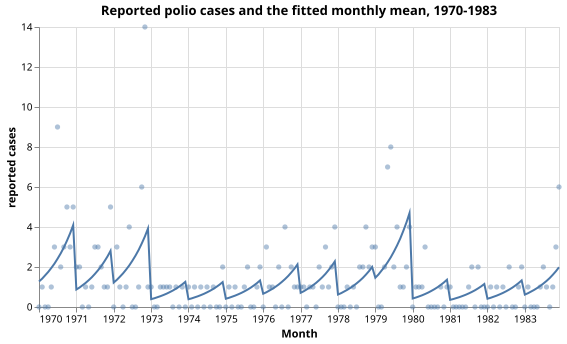

In [5]:
observed = pl.DataFrame({
    "date": series["date"].to_numpy(),
    "cases": series["cases"].to_numpy(),
})
fitted = pl.DataFrame({
    "date": series["date"].to_numpy(),
    "cases": np.round(fit.predict(type="response"), 3),
})

points = alt.Chart(observed).mark_circle(size=28, opacity=0.45).encode(
    x=alt.X("date:T", title="Month"),
    y=alt.Y("cases:Q", title="reported cases"),
)
mean_line = alt.Chart(fitted).mark_line().encode(x="date:T", y="cases:Q")
(points + mean_line).properties(
    title="Reported polio cases and the fitted monthly mean, 1970-1983",
    width=520, height=280,
)


## The fitted decade, month by month

Tuned on random months, the fit takes {eval}`int(fit.mstop)` steps. The
fitted mean follows the observed series: high in the early 1970s, low
through the mid-seventies, the resurgence of 1976–79 — the observed 1979
mean is 2.8 cases a month against 0.6 in 1974 — and low again after
1980. The month-of-year levels carry the seasonal peak, polio's
classical summer concentration: the observed August mean is 1.6 cases
against March's 0.3.

In [6]:
counts = fit.selection_counts(output="polars")

date_rows = counts.filter(pl.col("column") == "date")
date_updates = int(date_rows["updates"][0]) if date_rows.height else 0
year_share = float(counts.filter(pl.col("column") == "year")["share"][0])
counts


learner,column,updates,share
str,str,i64,f64
"""year""","""year""",142,0.830409
"""month""","""month""",29,0.169591
"""date""","""date""",0,0.0


## Update counts for year and month effects

The selection counts show which terms received the descriptive fit's updates: the year
levels took {eval}`f"{year_share:.0%}"` of the {eval}`int(fit.mstop)` updates
and the month levels the rest{eval}`f", and the date term {date_updates}" if "date" in rec.formula else ""`.
The year levels can follow the 1976–79 resurgence, which a single trend
cannot bend to. The year levels are priced against a log-linear trend with
month levels, on the same random folds.

In [7]:
# The log-linear trend against the year levels, each at its own best step
# count on the random folds that the description is judged on.
trend = mb.gamboost("cases ~ bols(date) + brandom(month)", data=series,
                    family=rec.family, control=mb.boost_control(1000, 0.1))
year_path = np.asarray(
    mb.gamboost(rec.formula, data=series, family=rec.family,
                control=mb.boost_control(1000, 0.1)).cvrisk(folds=random).aggregate)
trend_path = np.asarray(trend.cvrisk(folds=random).aggregate)
year_risk, trend_risk = float(year_path.min()), float(trend_path.min())

encoding_rows = pl.DataFrame([
    {"specification": "autospec's formula", "held-out risk": year_risk},
    {"specification": "log-linear trend + month levels", "held-out risk": trend_risk},
])
encoding_rows

/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/_workflow.py:191: UserWarning: boosting has undone much of the penalty of 1 learner(s): brandom(month): 12 of 12 df after 916 selections (one step: 2.2). Each selection fits a shrunken step, and the steps add up to the unpenalized fit on the learner's basis, so a penalty's df= no longer sets the term's flexibility. The predictions at this mstop already include that flexibility; the warning changes no fitted value. Choose mstop by cross-validation (cv_risk) rather than fitting this long, because cross-validation scores that flexibility out of fold. penalty_drift() lists every learner. Guide: python -m mboostrs guide fit-and-tune.
  return function(*args, **kwargs)
/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/_workflow.

specification,held-out risk
str,f64
"""autospec's formula""",1.530597
"""log-linear trend + month level…",1.589323


## Year effects and a log-linear trend

On random months the year levels describe the decade with held-out risk
{eval}`f"{year_risk:.4f}"`, and the log-linear trend with month levels
{eval}`f"{trend_risk:.4f}"`, {eval}`f"{abs(trend_risk - year_risk) / year_risk:.1%}"`
{eval}`"higher" if trend_risk > year_risk else "lower"`: on this series the
two encodings describe the months about equally well. The trend carries the
long decline, Zeger's conclusion about the rate; the year levels also carry
the local rise in 1976–79 that a single trend cannot fit{eval}`", and autospec, given both, dropped the trend term because it earned none of the risk reduction" if date_dropped else ""`.
The paired specifications therefore compare a single long-term trend with
separate year effects on the same interpolation task.

In [8]:
# The detected rolling origin against random rows, judged at the
# descriptive fit's step count so the comparison is the folds, not the tuning.
steps = int(fit.mstop)
rolling_risk = float(fit.cvrisk(folds=rolling, at_mstop=steps).aggregate[steps])
random_risk = float(fit.cvrisk(folds=random, at_mstop=steps).aggregate[steps])

fold_rows = pl.DataFrame([
    {"fold design": "random rows", "held-out risk": random_risk},
    {"fold design": "rolling origin", "held-out risk": rolling_risk},
])
fold_rows

/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/cvrisk.py:884: UserWarning: optimal mstop 171 is within 5% of the search cap 171; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  return CvRiskResult(


fold design,held-out risk
str,f64
"""random rows""",1.530597
"""rolling origin""",1.542994


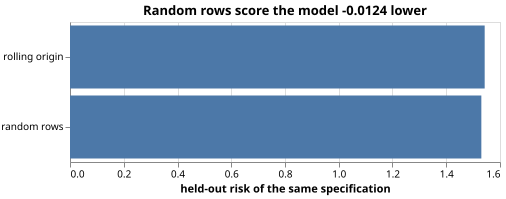

In [9]:
bars = alt.Chart(fold_rows).mark_bar().encode(
    y=alt.Y("fold design:N", title=None, sort="-x"),
    x=alt.X("held-out risk:Q", scale=alt.Scale(zero=False),
            title="held-out risk of the same specification"),
)
bars.properties(
    title=f"Random rows score the model {random_risk - rolling_risk:.4f} lower",
    width=430, height=140,
)


## Forecast and interpolation scores

Random rows score the same specification lower than the rolling origin,
and the two numbers answer different questions. Random rows ask how the
model interpolates within the fourteen years: every judged month sits with
its neighbours in training. The rolling origin asks what the past says
about the months that follow. `autospec` used the rolling origin
throughout, because the calendar named the folds before the first fit, and
on that design it found almost nothing to forecast with. A search whose folds ignore time order, such as random folds,
would have reported the interpolation number as if it were a
forecast.

Across the run, the family was chosen by a held-out measurement (a
Pearson dispersion of {eval}`f"{rec.evidence['family'].dispersion:.2f}"`), the
shape and step-count probes measured the forecast on folds that judge later
months, and the description of the decade was fitted and priced on folds
that interpolate. The share of zero months is reported where it arises.